In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("lainguyn123/student-performance-factors")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'student-performance-factors' dataset.
Path to dataset files: /kaggle/input/student-performance-factors


In [3]:
import os
print(os.listdir(path))

['StudentPerformanceFactors.csv']


In [4]:
import pandas as pd
df=pd.read_csv(os.path.join(path, "StudentPerformanceFactors.csv"))

In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [6]:
print(df.describe())

       Hours_Studied   Attendance  Sleep_Hours  Previous_Scores  \
count    6607.000000  6607.000000   6607.00000      6607.000000   
mean       19.975329    79.977448      7.02906        75.070531   
std         5.990594    11.547475      1.46812        14.399784   
min         1.000000    60.000000      4.00000        50.000000   
25%        16.000000    70.000000      6.00000        63.000000   
50%        20.000000    80.000000      7.00000        75.000000   
75%        24.000000    90.000000      8.00000        88.000000   
max        44.000000   100.000000     10.00000       100.000000   

       Tutoring_Sessions  Physical_Activity   Exam_Score  
count        6607.000000        6607.000000  6607.000000  
mean            1.493719           2.967610    67.235659  
std             1.230570           1.031231     3.890456  
min             0.000000           0.000000    55.000000  
25%             1.000000           2.000000    65.000000  
50%             1.000000           3.00000

In [12]:
cat_cols=df.select_dtypes(
    include=['object']
).columns
print(cat_cols)

Index(['Parental_Involvement', 'Access_to_Resources',
       'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access',
       'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence',
       'Learning_Disabilities', 'Parental_Education_Level',
       'Distance_from_Home', 'Gender'],
      dtype='object')


In [13]:
num_cols=df.select_dtypes(
    include=['int64','float64']
).columns
print(num_cols)

Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score'],
      dtype='object')


In [15]:
# seprate the target columns from this
target="Exam_Score"
numerical_features=[
    col for col in num_cols
    if col  != target
]

categorical_features=cat_cols

In [16]:
#                                           Numerical Vs Numerical Bivariate Analysis
# In this first we understand related between ever categorical colum with target columns with the scatter plot



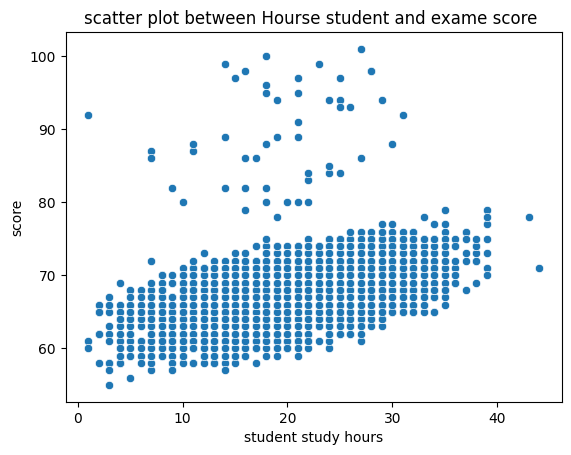

In [18]:
                                                          #1.1 Scatter_plot
import matplotlib.pyplot as plt
import seaborn as sns
sns.scatterplot(
    data=df,
    x="Hours_Studied",
    y="Exam_Score"
)

plt.title("scatter plot between Hourse student and exame score ")
plt.xlabel("student study hours")
plt.ylabel("score")
plt.show()

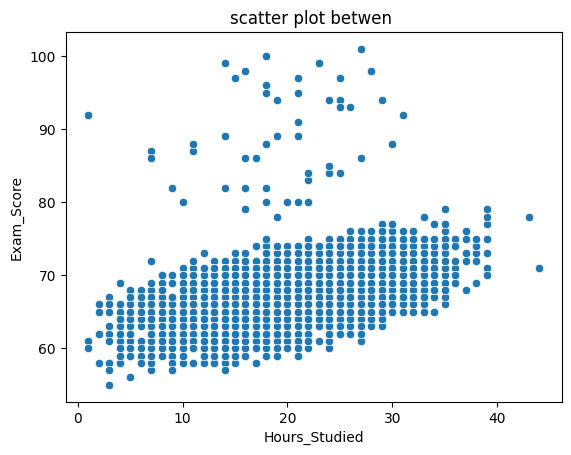

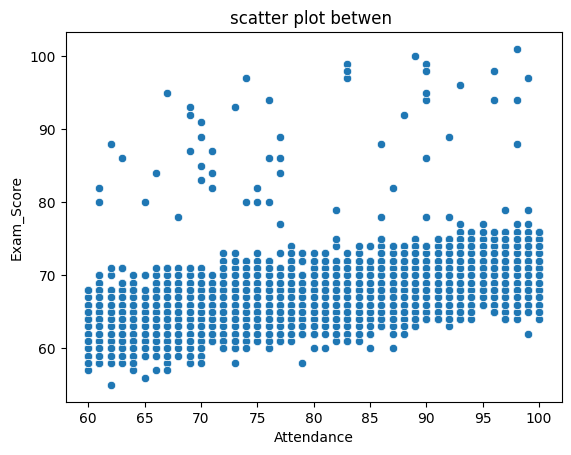

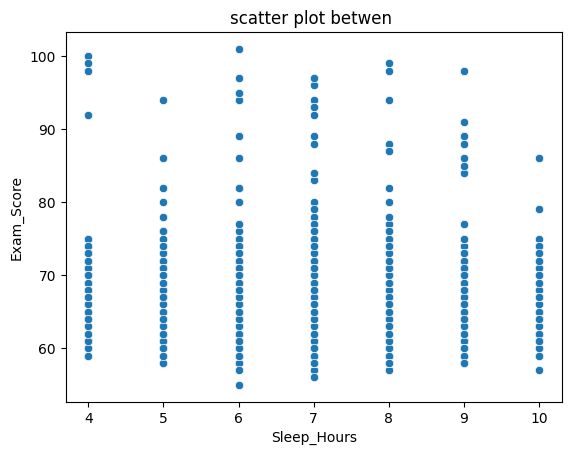

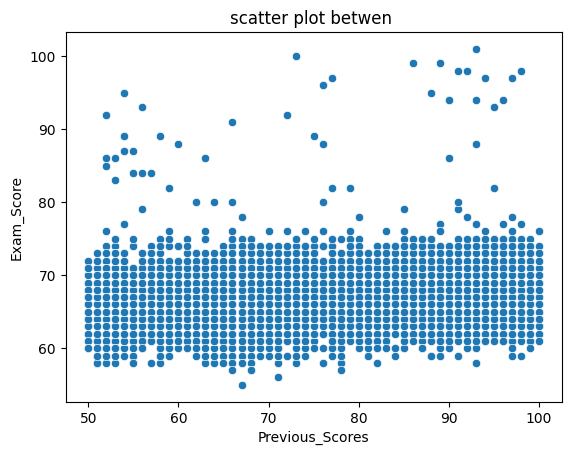

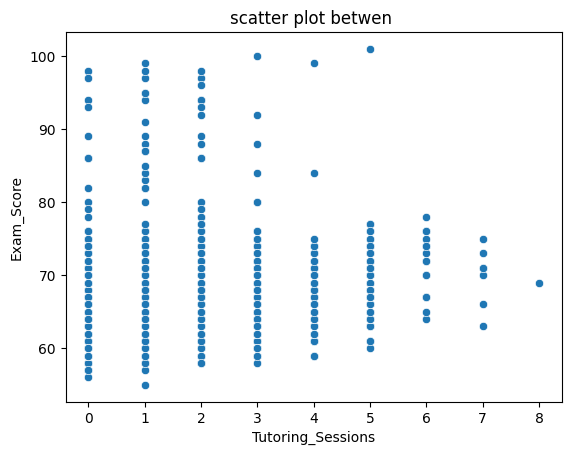

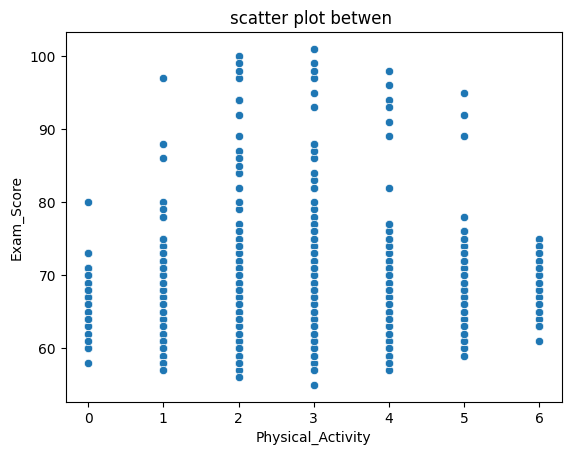

In [23]:
# Now can we apply this on every numerical feature with target featrue in one using loops
for col in numerical_features:
  sns.scatterplot(
      data=df,
      x=df[col],
      y="Exam_Score"
  )
  plt.title("scatter plot betwen ")
  plt.show()


In [24]:
                                                                  # 1.2 Covariance


covarience=df[
    ["Hours_Studied","Exam_Score"]
].cov()

print(covarience)

               Hours_Studied  Exam_Score
Hours_Studied      35.887221   10.381837
Exam_Score         10.381837   15.135646


In [25]:
                                                                  # 1.3Correlation

correlation=df[
    ["Hours_Studied","Exam_Score"]
].corr()

print(correlation)

               Hours_Studied  Exam_Score
Hours_Studied       1.000000    0.445455
Exam_Score          0.445455    1.000000


In [27]:
                                                                # 1.4 Pearson Correlation


pearson_corr = df[
    "Hours_Studied"
].corr(
    df["Exam_Score"],
    method="pearson"
)

print(pearson_corr)

0.44545495407528235


In [28]:
                                                                # 1.5 Spearman Rank Correlation


spearman_corr = df[
    "Hours_Studied"
].corr(
    df["Exam_Score"],
    method="spearman"
)

print(spearman_corr)

0.48095596242825545


In [29]:
                                                                  #1.6 Compare Pearson and Spearman together


x = "Hours_Studied"
y = "Exam_Score"

pearson = df[x].corr(df[y], method="pearson")
spearman = df[x].corr(df[y], method="spearman")

print("Pearson:", pearson)
print("Spearman:", spearman)

Pearson: 0.44545495407528235
Spearman: 0.48095596242825545


                   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  \
Hours_Studied           1.000000   -0.009908     0.010977         0.024846   
Attendance             -0.009908    1.000000    -0.015918        -0.020186   
Sleep_Hours             0.010977   -0.015918     1.000000        -0.021750   
Previous_Scores         0.024846   -0.020186    -0.021750         1.000000   
Tutoring_Sessions      -0.014282    0.014324    -0.012216        -0.013122   
Physical_Activity       0.004624   -0.022435    -0.000378        -0.011274   
Exam_Score              0.445455    0.581072    -0.017022         0.175079   

                   Tutoring_Sessions  Physical_Activity  Exam_Score  
Hours_Studied              -0.014282           0.004624    0.445455  
Attendance                  0.014324          -0.022435    0.581072  
Sleep_Hours                -0.012216          -0.000378   -0.017022  
Previous_Scores            -0.013122          -0.011274    0.175079  
Tutoring_Sessions        

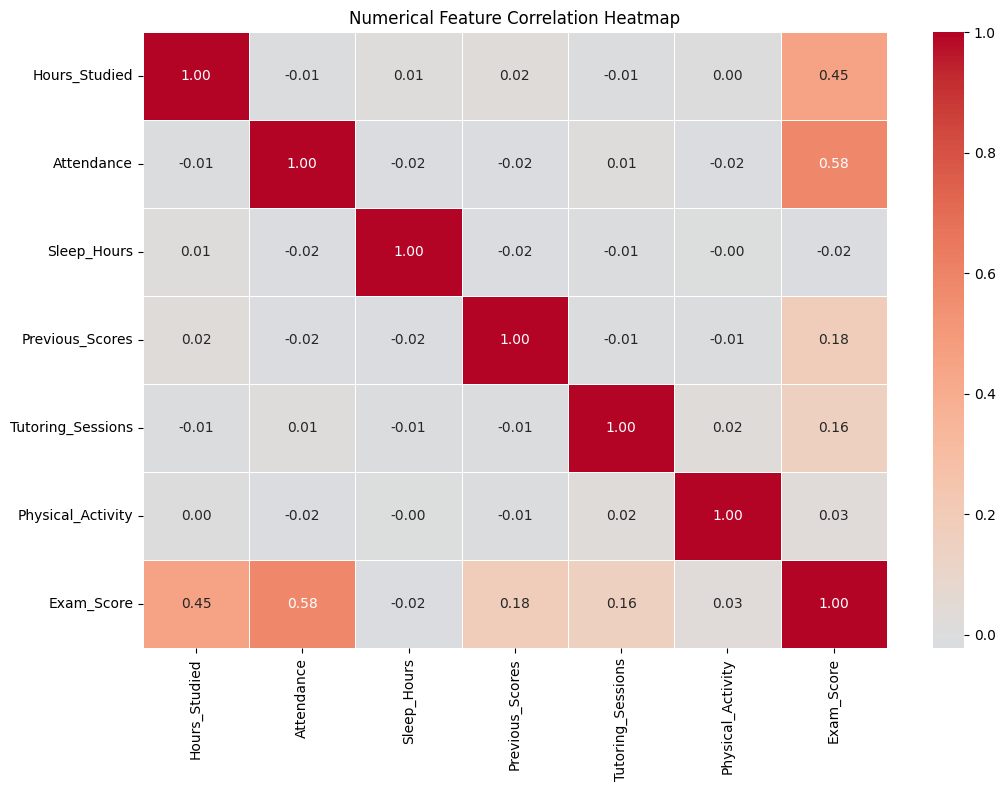

In [30]:
                                                                     #  2.Correlation Matrix and Heatmap
#A correlation matrix is a table that shows correlation coefficients between multiple numerical variables.

corr_matrix = df[
    num_cols
].corr(method="pearson")

print(corr_matrix)

#heatmap visualization
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Numerical Feature Correlation Heatmap")

plt.show()

In [31]:
target_corr = (
    corr_matrix["Exam_Score"]
    .drop("Exam_Score")
    .sort_values(ascending=False)
)

print(target_corr)

Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64


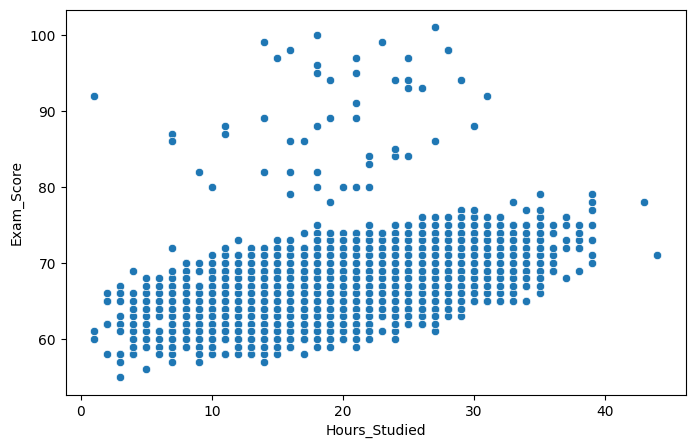

In [32]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Hours_Studied",
    y="Exam_Score"
)

plt.show()